# Text → Gloss tiếng Việt (ViT5) — bản chạy trên Kaggle
Đọc 17 file JSON theo chủ đề → làm sạch → tự chia train/val/test → fine-tune `VietAI/vit5-base` → đánh giá tổng và theo từng chủ đề → lưu model + metric.

**Thiết lập Kaggle trước khi chạy (panel bên phải):**
1. *Session options → Accelerator*: **GPU T4 x2**.
2. *Session options → Internet*: **On** (cần để tải model từ Hugging Face và cài `sacrebleu`).
3. *Input*: đã thêm dataset chứa 17 file JSON (sửa `DATA_PATH` ở mục 1 nếu đường dẫn khác).

**Thứ tự chạy:** chạy từ trên xuống. Có ô *smoke test* (chạy thử ~20 bước) tự dừng nếu loss bị `nan`, và các ô đánh giá/lưu model có chốt chặn `TRAINED` nên không đánh giá nhầm model chưa train.

**Lưu kết quả:** mọi thứ nằm trong `/kaggle/working/gloss_out/`. Thư mục này **mất khi hết session** nếu bạn không *Save Version* (xem mục 9).

In [1]:
!pip -q install "transformers>=4.50,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import importlib.metadata as md
for p in ["transformers", "tokenizers", "huggingface-hub"]:
    print(p, md.version(p))

transformers 4.57.6
tokenizers 0.22.2
huggingface-hub 0.36.2


## 0. Môi trường

In [3]:
import os, sys, subprocess, importlib.util
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Không dùng pip install -U: giữ nguyên bộ thư viện có sẵn của Kaggle, chỉ cài thứ còn thiếu
if importlib.util.find_spec("sacrebleu") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "sacrebleu"])

import torch, transformers, datasets, accelerate, sentencepiece, pandas, matplotlib, sacrebleu
for name, mod in [("torch", torch), ("transformers", transformers), ("datasets", datasets),
                  ("accelerate", accelerate), ("sentencepiece", sentencepiece),
                  ("sacrebleu", sacrebleu), ("pandas", pandas)]:
    print(f"{name:14s} {mod.__version__}")
print("-" * 40)
print("Số GPU:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} | {p.total_memory/2**30:.1f} GiB (mỗi card độc lập, không cộng dồn)")
assert torch.cuda.is_available(), "Chưa bật GPU: Session options -> Accelerator -> GPU T4 x2"

torch          2.11.0+cu130
transformers   4.57.6
datasets       4.8.5
accelerate     1.15.0
sentencepiece  0.2.2
sacrebleu      2.6.0
pandas         2.3.3
----------------------------------------
Số GPU: 2
  GPU 0: Tesla T4 | 14.6 GiB (mỗi card độc lập, không cộng dồn)
  GPU 1: Tesla T4 | 14.6 GiB (mỗi card độc lập, không cộng dồn)


## 1. Cấu hình và thư mục lưu kết quả

In [24]:
import os, json, shutil
from pathlib import Path

# ====== SỬA CÁC DÒNG NÀY ======
DATA_PATH  = "/kaggle/input/datasets/reinforceexercises/dataset/Data"   # thư mục chứa 17 file .json

TEXT_KEY   = "text"    # None = tự dò
GLOSS_KEY  = "Gloss"   # không phân biệt hoa/thường; None = tự dò

# "stratified": mỗi chủ đề đều có mặt trong train/val/test (nên dùng trước)
# "holdout_topics": giữ nguyên một số chủ đề làm test (đo khả năng tổng quát hoá sang chủ đề lạ)
SPLIT_MODE     = "stratified"
HOLDOUT_TOPICS = []            # vd ["du_lich", "y_te"] (tên file không có .json), chỉ dùng khi holdout_topics
VAL_RATIO, TEST_RATIO = 0.05, 0.05
SEED = 42

MODEL_NAME = "VietAI/vit5-base"
PREFIX     = "dịch sang gloss: "
MAX_LEN    = 128
EPOCHS     = 15
LR         = 1e-4
BATCH      = 16                 # batch MỖI GPU
GRAD_ACCUM = 1
EVAL_BEAMS = 4                 # số beam khi eval mỗi epoch (giảm xuống 2 nếu eval quá chậm)

USE_FP16   = True              # T4 không có bf16. Nếu loss thành nan: đặt False (fp32, chậm hơn)
RESUME     = True              # tự tiếp tục từ checkpoint-* nếu có
RUN_SMOKE_TEST = True          # chạy thử 20 bước trước khi train thật; đặt False khi đã ổn
SMOKE_STEPS    = 20
CLEAN_CHECKPOINTS_AT_END = True   # True: xoá checkpoints/ ở cuối để output nhẹ khi Save Version
# ===============================

# ----- thư mục output (tất cả nằm trong /kaggle/working nên được lưu khi Save Version) -----
OUTPUT_ROOT    = "/kaggle/working/gloss_out"
OUT_DIR        = OUTPUT_ROOT
CHECKPOINT_DIR = os.path.join(OUTPUT_ROOT, "checkpoints")
SMOKE_DIR      = os.path.join(OUTPUT_ROOT, "smoke_tmp")
MODEL_DIR      = os.path.join(OUTPUT_ROOT, "best_model")
PROCESSED_DIR  = os.path.join(OUTPUT_ROOT, "processed_data")
PREDICTION_DIR = os.path.join(OUTPUT_ROOT, "predictions")
METRICS_DIR    = os.path.join(OUTPUT_ROOT, "metrics")
LOG_DIR        = os.path.join(OUTPUT_ROOT, "logs")
for d in [OUTPUT_ROOT, CHECKPOINT_DIR, MODEL_DIR, PROCESSED_DIR, PREDICTION_DIR, METRICS_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

if not os.path.isdir(DATA_PATH):
    print("KHÔNG thấy DATA_PATH. Các thư mục đang có trong /kaggle/input:")
    for root, dirs, _ in os.walk("/kaggle/input"):
        print("  ", root)
        if root.count(os.sep) > 5: break
    raise FileNotFoundError(DATA_PATH)

TRAINED = False   # chốt chặn: chỉ đổi thành True sau khi train xong
print("Đã tạo thư mục output tại", OUTPUT_ROOT)

Đã tạo thư mục output tại /kaggle/working/gloss_out


## 2. Đọc dữ liệu và kiểm tra cấu trúc
Chịu được các dạng: list các dict, dict bọc list (`{"data": [...]}`), dict id→bản ghi, hoặc JSONL. **Xem phần in ra để chắc chắn key text/gloss đúng.**

In [5]:
import json, glob, unicodedata, re, hashlib
import pandas as pd
from pathlib import Path

files = sorted(glob.glob(os.path.join(DATA_PATH, "**", "*.json*"), recursive=True))
print(f"Tìm thấy {len(files)} file")
assert files, "Không thấy file json nào, kiểm tra lại DATA_PATH"

def read_records(path):
    raw = Path(path).read_text(encoding="utf-8").strip()
    try:
        obj = json.loads(raw)
    except json.JSONDecodeError:
        obj = [json.loads(l) for l in raw.splitlines() if l.strip()]   # JSONL
    if isinstance(obj, dict):
        lists = [v for v in obj.values() if isinstance(v, list) and v and isinstance(v[0], dict)]
        if lists:
            obj = max(lists, key=len)
        elif obj and all(isinstance(v, dict) for v in obj.values()):
            obj = list(obj.values())
        else:
            obj = [obj]
    return obj

TEXT_CANDS  = ["text","vi","vietnamese","sentence","input","source","src","câu","cau","question","utterance"]
GLOSS_CANDS = ["gloss","glosses","target","output","tgt","label","sign","ky_hieu"]

def pick_key(keys, cands, override):
    low = {k.lower(): k for k in keys}
    if override:
        assert override.lower() in low, f"Key '{override}' không có. Các key hiện có: {list(keys)}"
        return low[override.lower()]
    for c in cands:
        if c in low: return low[c]
    raise KeyError(f"Không tự dò được key. Các key hiện có: {list(keys)}. Hãy đặt TEXT_KEY/GLOSS_KEY.")

raw_by_topic = {}
for f in files:
    recs = read_records(f)
    topic = Path(f).stem
    raw_by_topic[topic] = recs
    print(f"- {topic}: {len(recs)} bản ghi | keys: {list(recs[0].keys())}")

first = next(iter(raw_by_topic.values()))[0]
print("\nVí dụ bản ghi đầu tiên:\n", json.dumps(first, ensure_ascii=False, indent=2)[:800])

Tìm thấy 18 file
- 1000_cau_dong_vat_thien_nhien_cay_co: 998 bản ghi | keys: ['text', 'Gloss']
- anuong: 500 bản ghi | keys: ['text', 'Gloss']
- camxucvatrangthaicothe: 989 bản ghi | keys: ['text', 'Gloss']
- cau_bo_sung_gloss3: 5752 bản ghi | keys: ['text', 'Gloss']
- dia_danh_di_tich_lich_su_van_hoa_500: 500 bản ghi | keys: ['text', 'Gloss']
- ditichlichsuvanhoa: 274 bản ghi | keys: ['text', 'Gloss']
- giai_tri_the_thao_nghe_thuat_500: 498 bản ghi | keys: ['text', 'Gloss']
- giaitrivanghethuat: 568 bản ghi | keys: ['text', 'Gloss']
- giao_tiep_hang_ngay: 461 bản ghi | keys: ['text', 'Gloss']
- giao_tiep_thong_tin_gia_dinh: 356 bản ghi | keys: ['text', 'Gloss']
- giaothong: 300 bản ghi | keys: ['text', 'Gloss']
- hoatdonghangngay: 500 bản ghi | keys: ['text', 'Gloss']
- ouput: 5446 bản ghi | keys: ['text', 'Gloss']
- thien_nhien_dong_vat_thuc_vat_500: 500 bản ghi | keys: ['text', 'Gloss']
- thiennhien: 320 bản ghi | keys: ['text', 'Gloss']
- thoigianlete_lehoi: 300 bản ghi | keys: ['t

## 3. Làm sạch và chia train / val / test

In [6]:
from collections import Counter

def nfc(s): return re.sub(r"\s+", " ", unicodedata.normalize("NFC", str(s))).strip()
def to_str(v): return nfc(v)

def gloss_to_str(v):
    # ["hôm nay","tôi","cảm thấy"] -> "hôm_nay tôi cảm_thấy" (mỗi token = 1 ký hiệu)
    if isinstance(v, list):
        return " ".join(nfc(x).replace(" ", "_") for x in v if nfc(x))
    return nfc(v)

def group_key(s):
    # chuẩn hoá mạnh để các câu "gần trùng" luôn rơi vào cùng một split
    s = s.lower()
    s = re.sub(r"[^\w\s]", "", s)
    return re.sub(r"\s+", " ", s).strip()

rows, skipped, used_keys = [], 0, {}
for topic, recs in raw_by_topic.items():
    tk = pick_key(recs[0].keys(), TEXT_CANDS, TEXT_KEY)
    gk = pick_key(recs[0].keys(), GLOSS_CANDS, GLOSS_KEY)
    used_keys[topic] = (tk, gk)
    for r in recs:
        if tk not in r or gk not in r:
            skipped += 1; continue
        rows.append({"topic": topic, "text": to_str(r[tk]), "gloss": gloss_to_str(r[gk])})
if len(set(used_keys.values())) > 1:
    print("CẢNH BÁO: các file dùng key khác nhau:", used_keys)
else:
    print("Key dùng cho mọi file (text, gloss):", next(iter(used_keys.values())))

df = pd.DataFrame(rows)
print(f"Bản ghi thiếu key (bị bỏ qua): {skipped}")
n0 = len(df)
df = df[(df.text != "") & (df.gloss != "")]
df = df.drop_duplicates(subset=["text", "gloss"]).reset_index(drop=True)
df["gkey"] = df.text.map(group_key)
same = (df.gloss.str.replace("_", " ") == df.text).mean()
print(f"Tỷ lệ gloss giống hệt câu gốc (sau khi bỏ '_'): {same:.2%}")
print(f"Số token gloss TB/câu: {df.gloss.str.split().map(len).mean():.1f} | số từ TB/câu: {df.text.str.split().map(len).mean():.1f}")
print(f"Tổng: {n0} -> sau làm sạch/bỏ trùng: {len(df)}")

conf = df.groupby("gkey").gloss.nunique()
print(f"Số câu có >1 gloss khác nhau (nhãn mâu thuẫn): {(conf > 1).sum()}")

def hash01(key):
    h = hashlib.md5(f"{SEED}-{key}".encode("utf-8")).hexdigest()
    return int(h[:8], 16) / 0xFFFFFFFF

def assign(row):
    r = hash01(row.gkey)               # cùng gkey => cùng split => không rò rỉ
    if SPLIT_MODE == "holdout_topics":
        if row.topic in HOLDOUT_TOPICS: return "test"
        return "val" if r < VAL_RATIO else "train"
    if r < TEST_RATIO: return "test"
    if r < TEST_RATIO + VAL_RATIO: return "val"
    return "train"

if SPLIT_MODE == "holdout_topics":
    assert HOLDOUT_TOPICS, "Hãy điền HOLDOUT_TOPICS"
df["split"] = df.apply(assign, axis=1)

print("\nSố mẫu theo chủ đề x split:")
print(pd.crosstab(df.topic, df.split, margins=True))

sets = {s: set(df[df.split == s].gkey) for s in ["train", "val", "test"]}
print("\nGiao train∩val:", len(sets["train"] & sets["val"]),
      "| train∩test:", len(sets["train"] & sets["test"]),
      "| val∩test:", len(sets["val"] & sets["test"]))

# lưu split (jsonl + theo từng chủ đề đúng định dạng gốc)
for s in ["train", "val", "test"]:
    df[df.split == s][["topic", "text", "gloss"]].to_json(
        f"{PROCESSED_DIR}/{s}.jsonl", orient="records", lines=True, force_ascii=False)
    for topic, g in df[df.split == s].groupby("topic"):
        d = Path(PROCESSED_DIR) / "split_json" / s; d.mkdir(parents=True, exist_ok=True)
        recs_ = [{"text": t, "Gloss": [x.replace("_", " ") for x in gl.split()]} for t, gl in zip(g.text, g.gloss)]
        (d / f"{topic}.json").write_text(json.dumps(recs_, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\nĐã lưu split vào {PROCESSED_DIR}/(train|val|test).jsonl và {PROCESSED_DIR}/split_json/")

# thống kê từ vựng gloss
cnt = Counter(t for g in df[df.split == "train"].gloss for t in g.split())
vocab = set(cnt)
test_tokens = [t for g in df[df.split == "test"].gloss for t in g.split()]
oov = sum(t not in vocab for t in test_tokens) / max(1, len(test_tokens))
print(f"Gloss vocab (train): {len(vocab)} token | token chỉ xuất hiện 1 lần: {sum(v == 1 for v in cnt.values())}")
print(f"Tỷ lệ token gloss trong test KHÔNG có trong train (OOV): {oov:.2%}")

# Kho ký hiệu của TOÀN BỘ dữ liệu (gồm cả test): dùng làm danh mục ánh xạ video, KHÔNG dùng để diễn giải OOV
all_cnt = Counter(t.replace("_", " ") for g in df.gloss for t in g.split())
ALL_SIGNS = set(all_cnt)
json.dump(dict(all_cnt.most_common()), open(f"{PROCESSED_DIR}/gloss_vocab.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)
print(f"Đã lưu kho {len(ALL_SIGNS)} ký hiệu vào {PROCESSED_DIR}/gloss_vocab.json")

frac_upper = df.text.map(lambda t: t != t.lower()).mean()
frac_punct = df.text.str.contains(r"[^\w\s]").mean()
TEXT_IS_PLAIN = bool(frac_upper < 0.01 and frac_punct < 0.01)
print(f"Câu có viết hoa: {frac_upper:.1%} | có dấu câu: {frac_punct:.1%} | chuẩn hoá đầu vào khi suy luận: {TEXT_IS_PLAIN}")
json.dump({"TEXT_IS_PLAIN": TEXT_IS_PLAIN, "PREFIX": PREFIX, "MAX_LEN": MAX_LEN},
          open(f"{PROCESSED_DIR}/infer_config.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

Key dùng cho mọi file (text, gloss): ('text', 'Gloss')
Bản ghi thiếu key (bị bỏ qua): 2
Tỷ lệ gloss giống hệt câu gốc (sau khi bỏ '_'): 41.12%
Số token gloss TB/câu: 3.7 | số từ TB/câu: 6.5
Tổng: 20746 -> sau làm sạch/bỏ trùng: 15283
Số câu có >1 gloss khác nhau (nhãn mâu thuẫn): 2

Số mẫu theo chủ đề x split:
split                                 test  train  val    All
topic                                                        
1000_cau_dong_vat_thien_nhien_cay_co    57    897   44    998
anuong                                  19    465   16    500
camxucvatrangthaicothe                  57    889   43    989
cau_bo_sung_gloss3                     299   5184  264   5747
dia_danh_di_tich_lich_su_van_hoa_500    27    443   30    500
ditichlichsuvanhoa                      10    246   18    274
giai_tri_the_thao_nghe_thuat_500        29    444   25    498
giaitrivanghethuat                      26    514   28    568
giao_tiep_hang_ngay                     10    211   17    238
giao_t

## 4. Tokenizer, mô hình, kiểm tra độ dài

In [7]:
import gc, math, numpy as np
from datasets import Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments, EarlyStoppingCallback,
                          TrainerCallback, set_seed)
set_seed(SEED)

def load_tokenizer(name):
    # transformers 5.x có thể lỗi khi dựng tokenizer nhanh của T5 từ spiece.model -> thử lần lượt các cách
    attempts = [
        ("AutoTokenizer (fast)",       lambda: AutoTokenizer.from_pretrained(name)),
        ("AutoTokenizer use_fast=False", lambda: AutoTokenizer.from_pretrained(name, use_fast=False)),
        ("T5Tokenizer",                lambda: __import__("transformers").T5Tokenizer.from_pretrained(name)),
    ]
    errs = []
    for label, fn in attempts:
        try:
            t = fn()
            print(f"Tokenizer OK bằng: {label} -> {type(t).__name__}")
            return t
        except Exception as e:
            errs.append(f"{label}: {type(e).__name__}: {str(e)[:150]}")
            print(f"[thất bại] {errs[-1]}")
    raise RuntimeError("Không tải được tokenizer bằng cả 3 cách. Cách cuối: "
                       "!pip -q install \"transformers>=4.50,<5\" rồi Restart session và chạy lại từ đầu "
                       "(bỏ qua mọi lệnh pip install -U).\n" + "\n".join(errs))

def load_model():
    m = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    m.config.use_cache = False          # bắt buộc khi bật gradient checkpointing
    return m

tok = load_tokenizer(MODEL_NAME)

# kiểm tra token hoá gloss + độ dài
samp = df[df.split == "train"].sample(min(3000, (df.split == "train").sum()), random_state=SEED)
len_src = [len(tok(PREFIX + t).input_ids) for t in samp.text]
len_tgt = [len(tok(text_target=g).input_ids) for g in samp.gloss]
print("Độ dài nguồn  p50/p95/p99/max:", [int(np.percentile(len_src, p)) for p in (50, 95, 99, 100)])
print("Độ dài đích   p50/p95/p99/max:", [int(np.percentile(len_tgt, p)) for p in (50, 95, 99, 100)])
print(f"MAX_LEN={MAX_LEN}: nguồn bị cắt {np.mean(np.array(len_src) > MAX_LEN):.2%}, đích bị cắt {np.mean(np.array(len_tgt) > MAX_LEN):.2%}")
print("Ví dụ token hoá gloss:", tok.tokenize(samp.gloss.iloc[0])[:25])
print("Tỷ lệ gloss mẫu có <unk>:", np.mean([tok.unk_token_id in tok(text_target=g).input_ids for g in samp.gloss]))

def preprocess(batch):
    enc = tok([PREFIX + t for t in batch["text"]], max_length=MAX_LEN, truncation=True)
    enc["labels"] = tok(text_target=batch["gloss"], max_length=MAX_LEN, truncation=True)["input_ids"]
    return enc

raw = DatasetDict({s: Dataset.from_pandas(df[df.split == s][["text", "gloss"]].reset_index(drop=True))
                   for s in ["train", "val", "test"]})
ds = raw.map(preprocess, batched=True, remove_columns=["text", "gloss"])
print(ds)

I0000 00:00:1793745897.811170      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/820k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Tokenizer OK bằng: AutoTokenizer (fast) -> T5TokenizerFast
Độ dài nguồn  p50/p95/p99/max: [12, 18, 21, 29]
Độ dài đích   p50/p95/p99/max: [11, 20, 27, 38]
MAX_LEN=128: nguồn bị cắt 0.00%, đích bị cắt 0.00%
Ví dụ token hoá gloss: ['▁đất', '_', 'ru', 'ộng', '▁khô', '▁không', '_', 'có']
Tỷ lệ gloss mẫu có <unk>: 0.0003333333333333333


Map:   0%|          | 0/13785 [00:00<?, ? examples/s]

Map:   0%|          | 0/732 [00:00<?, ? examples/s]

Map:   0%|          | 0/766 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 13785
    })
    val: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 732
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 766
    })
})


## 5. Cấu hình huấn luyện (chưa train)
> **Lưu ý:** T5/ViT5 dễ bị `nan` khi dùng fp16. Ô smoke test bên dưới sẽ phát hiện sớm. Nếu `nan`: đặt `USE_FP16 = False` ở mục 1 và chạy lại từ ô này (hoặc đổi `MODEL_NAME = "vinai/bartpho-syllable"`).
> Trên 2 GPU, Trainer chạy DataParallel: **batch hiệu dụng = BATCH × số GPU × GRAD_ACCUM**.

In [14]:
import dataclasses, subprocess

n_gpu = torch.cuda.device_count()
eff_batch = BATCH * max(1, n_gpu) * GRAD_ACCUM
n_train = len(ds["train"])
steps_per_epoch = math.ceil(n_train / eff_batch)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(0.05 * total_steps)
print(f"n_gpu={n_gpu} | batch/GPU={BATCH} | grad_accum={GRAD_ACCUM} | batch hiệu dụng={eff_batch}")
print(f"n_train={n_train} | bước/epoch≈{steps_per_epoch} | tổng bước tối đa≈{total_steps} | warmup={warmup_steps}")
print("fp16:", USE_FP16, "| bf16: False (T4 không hỗ trợ bf16 thật sự)")

def decode_pair(p):
    preds, labels = p
    if isinstance(preds, tuple): preds = preds[0]
    preds  = np.where(preds  != -100, preds,  tok.pad_token_id)
    labels = np.where(labels != -100, labels, tok.pad_token_id)
    return (tok.batch_decode(preds, skip_special_tokens=True),
            tok.batch_decode(labels, skip_special_tokens=True))

def gloss_wer(preds, refs):
    # xấp xỉ tỷ lệ lỗi theo token bằng difflib.SequenceMatcher (KHÔNG phải WER chuẩn)
    import difflib
    errs = tot = 0
    for p, r in zip(preds, refs):
        p, r = p.split(), r.split()
        sm = difflib.SequenceMatcher(None, r, p)
        match = sum(b.size for b in sm.get_matching_blocks())
        errs += max(len(r), len(p)) - match; tot += len(r)
    return errs / max(1, tot)

def compute_metrics(p):
    pt, rt = decode_pair(p)
    return {"bleu": sacrebleu.corpus_bleu(pt, [rt], tokenize="none").score,
            "chrf": sacrebleu.corpus_chrf(pt, [rt]).score,
            "exact_match": float(np.mean([a.strip() == b.strip() for a, b in zip(pt, rt)])),
            "gloss_err": gloss_wer(pt, rt)}

class NaNStop(TrainerCallback):
    # dừng sớm nếu loss là nan/inf (hay gặp với T5 + fp16)
    def __init__(self): self.hit = False
    def on_log(self, args, state, control, logs=None, **kw):
        v = (logs or {}).get("loss")
        if v is not None and not math.isfinite(v):
            self.hit = True
            control.should_training_stop = True
            print(f"!!! loss = {v} tại step {state.global_step} -> dừng huấn luyện")

_valid_args = {f.name for f in dataclasses.fields(Seq2SeqTrainingArguments)}
def make_args(**over):
    kw = dict(
        output_dir=CHECKPOINT_DIR, logging_dir=LOG_DIR,
        learning_rate=LR, per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        gradient_accumulation_steps=GRAD_ACCUM, num_train_epochs=EPOCHS,
        weight_decay=0.01, label_smoothing_factor=0.1, warmup_steps=warmup_steps,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=2, save_only_model=False,
        load_best_model_at_end=True, metric_for_best_model="bleu", greater_is_better=True,
        predict_with_generate=True, generation_num_beams=EVAL_BEAMS, generation_max_length=MAX_LEN,
        fp16=USE_FP16, bf16=False,
        gradient_checkpointing=False, gradient_checkpointing_kwargs={"use_reentrant": False},
        dataloader_num_workers=2,
        logging_steps=50, seed=SEED, report_to="none",
    )
    kw.update(over)
    dropped = [k for k in kw if k not in _valid_args]
    if dropped: print("Bỏ tham số không tồn tại ở phiên bản transformers này:", dropped)
    return Seq2SeqTrainingArguments(**{k: v for k, v in kw.items() if k in _valid_args})

def make_trainer(m, train_ds, eval_ds, args, callbacks):
    return Seq2SeqTrainer(model=m, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                          data_collator=DataCollatorForSeq2Seq(tok, model=m),
                          compute_metrics=compute_metrics, callbacks=callbacks)

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

print("Đã định nghĩa cấu hình (chưa train).")

n_gpu=2 | batch/GPU=16 | grad_accum=1 | batch hiệu dụng=32
n_train=13785 | bước/epoch≈431 | tổng bước tối đa≈6465 | warmup=323
fp16: True | bf16: False (T4 không hỗ trợ bf16 thật sự)
Đã định nghĩa cấu hình (chưa train).


### 5b. Smoke test (chạy thử ngắn, model dùng xong sẽ bị bỏ)

In [15]:
if RUN_SMOKE_TEST:
    m_s = load_model()
    n_s = min(SMOKE_STEPS * eff_batch, n_train)
    args_s = make_args(output_dir=SMOKE_DIR, max_steps=SMOKE_STEPS, num_train_epochs=1, warmup_steps=0,
                       eval_strategy="no", save_strategy="no", load_best_model_at_end=False,
                       metric_for_best_model=None, logging_steps=5)
    tr_s = make_trainer(m_s, ds["train"].select(range(n_s)), ds["val"].select(range(min(64, len(ds["val"])))),
                        args_s, callbacks=[])
    tr_s.train()
    print(subprocess.run(["nvidia-smi", "--query-gpu=index,memory.used,memory.total,utilization.gpu",
                          "--format=csv"], capture_output=True, text=True).stdout)
    losses = [h["loss"] for h in tr_s.state.log_history if "loss" in h]
    print("Loss các lần log:", [round(x, 4) for x in losses])
    ev = tr_s.evaluate()          # thử luôn đường generate + compute_metrics
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ev.items()})
    ok = bool(losses) and all(math.isfinite(x) and x != 0.0 for x in losses)
    del tr_s, m_s; free_gpu()
    shutil.rmtree(SMOKE_DIR, ignore_errors=True)
    assert ok, "Loss là nan/0.0 -> đặt USE_FP16 = False (hoặc đổi model) rồi chạy lại từ mục 5."
    print("SMOKE TEST ĐẠT (loss hữu hạn). Model dùng thử đã bỏ, train thật sẽ nạp model mới.")
else:
    print("Bỏ qua smoke test.")

Step,Training Loss
5,6.387200
10,3.381300
15,2.691100
20,2.453200


index, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
0, 9975 MiB, 15360 MiB, 98 %
1, 3269 MiB, 15360 MiB, 94 %

Loss các lần log: [6.3872, 3.3813, 2.6911, 2.4532]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 2.4147, 'eval_bleu': 29.7423, 'eval_chrf': 65.4383, 'eval_exact_match': 0.375, 'eval_gloss_err': 0.7368, 'eval_runtime': 8.6424, 'eval_samples_per_second': 7.405, 'eval_steps_per_second': 0.231, 'epoch': 1.0}
SMOKE TEST ĐẠT (loss hữu hạn). Model dùng thử đã bỏ, train thật sẽ nạp model mới.


## 5c. Train thật
Tự tiếp tục từ `checkpoint-*` nếu có (và `RESUME=True`). Lịch sử loss/metric luôn được lưu vào `metrics/` kể cả khi bị ngắt giữa chừng.

In [16]:
import glob
model = load_model()
nan_cb = NaNStop()
trainer = make_trainer(model, ds["train"], ds["val"], make_args(),
                       callbacks=[EarlyStoppingCallback(early_stopping_patience=3), nan_cb])

has_ckpt = RESUME and bool(glob.glob(os.path.join(CHECKPOINT_DIR, "checkpoint-*")))
print("Resume từ checkpoint:" , has_ckpt)
try:
    trainer.train(resume_from_checkpoint=True if has_ckpt else None)
finally:
    hist = trainer.state.log_history
    pd.DataFrame(hist).to_csv(f"{METRICS_DIR}/log_history.csv", index=False)
    json.dump(hist, open(f"{METRICS_DIR}/log_history.json", "w"), ensure_ascii=False, indent=1)
    print("Đã lưu lịch sử huấn luyện vào", METRICS_DIR)

if nan_cb.hit:
    print("Huấn luyện dừng vì loss nan -> đặt USE_FP16 = False và chạy lại từ mục 5.")
else:
    TRAINED = True
    print("TRAIN XONG. best checkpoint:", trainer.state.best_model_checkpoint)

Resume từ checkpoint: False


Epoch,Training Loss,Validation Loss,Bleu,Chrf,Exact Match,Gloss Err
1,1.750500,1.659937,89.817202,95.614943,0.829235,0.062825
2,1.574400,1.554311,93.914274,96.987578,0.887978,0.038662
3,1.514000,1.511288,95.765600,98.337403,0.927596,0.026394
4,1.483600,1.485660,96.010273,98.482509,0.931694,0.025279
5,1.469500,1.487558,96.684300,98.760799,0.938525,0.022677
6,1.455200,1.480670,96.425478,98.757959,0.938525,0.023048
7,1.446800,1.478733,96.451433,98.819137,0.939891,0.021933
8,1.439800,1.471771,96.905824,98.829387,0.945355,0.020074
9,1.434500,1.471457,97.072100,98.966768,0.949454,0.019331
10,1.431400,1.468575,97.052627,98.757759,0.943989,0.019331


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

Đã lưu lịch sử huấn luyện vào /kaggle/working/gloss_out/metrics
TRAIN XONG. best checkpoint: /kaggle/working/gloss_out/checkpoints/checkpoint-3879


In [12]:
   # del trainer, model
   # free_gpu()

## 6. Chẩn đoán bias/variance: đường loss

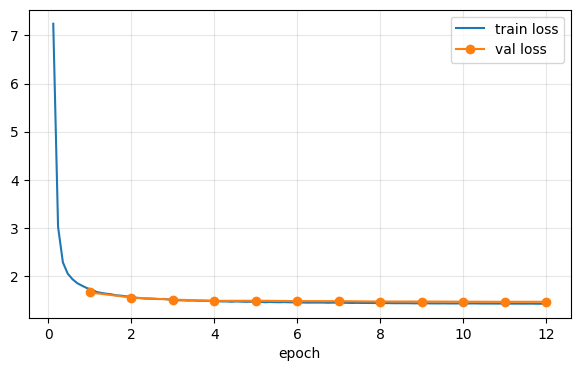

 epoch  eval_loss  eval_bleu  eval_chrf  eval_exact_match  eval_gloss_err
   1.0   1.659937  89.817202  95.614943          0.829235        0.062825
   2.0   1.554311  93.914274  96.987578          0.887978        0.038662
   3.0   1.511288  95.765600  98.337403          0.927596        0.026394
   4.0   1.485660  96.010273  98.482509          0.931694        0.025279
   5.0   1.487558  96.684300  98.760799          0.938525        0.022677
   6.0   1.480670  96.425478  98.757959          0.938525        0.023048
   7.0   1.478733  96.451433  98.819137          0.939891        0.021933
   8.0   1.471771  96.905824  98.829387          0.945355        0.020074
   9.0   1.471457  97.072100  98.966768          0.949454        0.019331
  10.0   1.468575  97.052627  98.757759          0.943989        0.019331
  11.0   1.465510  96.829825  98.768071          0.942623        0.020074
  12.0   1.466951  96.732444  98.874240          0.945355        0.020074


In [17]:
import matplotlib.pyplot as plt
h = pd.DataFrame(trainer.state.log_history)
tr = h[h.loss.notna()][["epoch", "loss"]] if "loss" in h else None
ev = h[h.eval_loss.notna()][["epoch", "eval_loss"]] if "eval_loss" in h else None
plt.figure(figsize=(7, 4))
if tr is not None: plt.plot(tr.epoch, tr.loss, label="train loss")
if ev is not None: plt.plot(ev.epoch, ev.eval_loss, "o-", label="val loss")
plt.xlabel("epoch"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{METRICS_DIR}/loss_curve.png", dpi=150, bbox_inches="tight"); plt.show()
if "eval_bleu" in h:
    print(h[h.eval_bleu.notna()][["epoch", "eval_loss", "eval_bleu", "eval_chrf", "eval_exact_match", "eval_gloss_err"]].to_string(index=False))

## 7. Đánh giá cuối trên test + theo từng chủ đề
Chạy ô này **một lần** sau khi đã chốt cấu hình, để test không bị "nhiễm". Có chốt chặn `TRAINED`.

In [18]:
assert TRAINED, "Chưa train xong (TRAINED=False). Chạy mục 5c trước."
model.config.use_cache = True   # bật lại cho giai đoạn sinh
out = trainer.predict(ds["test"], max_length=MAX_LEN, num_beams=4)
pt, rt = decode_pair((out.predictions, out.label_ids))
test_df = df[df.split == "test"].reset_index(drop=True).copy()
test_df["pred"] = pt
test_df["exact"] = [a.strip() == b.strip() for a, b in zip(pt, test_df.gloss)]

overall = {k: float(v) for k, v in compute_metrics((out.predictions, out.label_ids)).items()}
print("=== TỔNG TRÊN TEST ===")
print({k: round(v, 4) for k, v in overall.items()})

rows = []
for topic, g in test_df.groupby("topic"):
    rows.append({"topic": topic, "n": len(g),
                 "bleu": sacrebleu.corpus_bleu(g.pred.tolist(), [g.gloss.tolist()], tokenize="none").score,
                 "exact_match": g.exact.mean(),
                 "gloss_err": gloss_wer(g.pred.tolist(), g.gloss.tolist())})
per_topic = pd.DataFrame(rows).sort_values("bleu")
print("\n=== THEO CHỦ ĐỀ (xếp từ yếu đến mạnh) ===")
print(per_topic.round(3).to_string(index=False))

pred_oov = np.mean([t not in vocab for p in pt for t in p.split()])
print(f"\nTỷ lệ token dự đoán KHÔNG thuộc từ vựng gloss của train: {pred_oov:.2%}")

test_df["Gloss_ref"]  = [[x.replace("_", " ") for x in g.split()] for g in test_df.gloss]
test_df["Gloss_pred"] = [[x.replace("_", " ") for x in g.split()] for g in test_df.pred]
unk_rate = np.mean([x not in ALL_SIGNS for g in test_df.Gloss_pred for x in g])
print(f"Tỷ lệ ký hiệu dự đoán KHÔNG có trong kho ký hiệu (không ánh xạ được video): {unk_rate:.2%}")

# ----- lưu kết quả -----
test_df.to_json(f"{PREDICTION_DIR}/test_predictions.jsonl", orient="records", lines=True, force_ascii=False)
per_topic.to_csv(f"{METRICS_DIR}/per_topic_test.csv", index=False)
json.dump({**overall, "pred_oov_vs_train": float(pred_oov), "pred_unknown_vs_all_signs": float(unk_rate)},
          open(f"{METRICS_DIR}/test_overall.json", "w"), indent=1)
print("Đã lưu:", f"{PREDICTION_DIR}/test_predictions.jsonl,", f"{METRICS_DIR}/per_topic_test.csv, test_overall.json")

wrong = test_df[~test_df.exact]
wrong = wrong.sample(min(30, len(wrong)), random_state=SEED)
print("\n=== 30 CÂU SAI NGẪU NHIÊN (dùng cho phân tích lỗi) ===")
for _, r in wrong.iterrows():
    print(f"[{r.topic}]\n  VI  : {r.text}\n  REF : {r.gloss}\n  PRED: {r.pred}\n")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


=== TỔNG TRÊN TEST ===
{'bleu': 98.0951, 'chrf': 98.8349, 'exact_match': 0.9517, 'gloss_err': 0.0158}

=== THEO CHỦ ĐỀ (xếp từ yếu đến mạnh) ===
                               topic   n   bleu  exact_match  gloss_err
                               ouput   8 51.731        0.625      0.167
                 giao_tiep_hang_ngay  10 58.444        0.600      0.192
                    hoatdonghangngay  22 78.031        0.682      0.085
                  cau_bo_sung_gloss3 299 82.495        0.753      0.077
1000_cau_dong_vat_thien_nhien_cay_co  57 87.648        0.789      0.053
                  giaitrivanghethuat  26 87.784        0.808      0.053
                           truonghoc  98 88.777        0.786      0.054
dia_danh_di_tich_lich_su_van_hoa_500  27 89.574        0.704      0.084
        giao_tiep_thong_tin_gia_dinh  20 90.029        0.800      0.081
    giai_tri_the_thao_nghe_thuat_500  29 92.007        0.828      0.042
                  ditichlichsuvanhoa  10 93.309        0.800   

## 8. Lưu mô hình và suy luận thử

In [19]:
assert TRAINED, "Chưa train xong (TRAINED=False)."
model.config.use_cache = True        # lưu config với use_cache=True để suy luận sau này nhanh
trainer.save_model(MODEL_DIR)        # best model (do load_best_model_at_end=True)
tok.save_pretrained(MODEL_DIR)
json.dump({"MODEL_NAME": MODEL_NAME, "PREFIX": PREFIX, "MAX_LEN": MAX_LEN, "EPOCHS": EPOCHS, "LR": LR,
           "BATCH_PER_GPU": BATCH, "GRAD_ACCUM": GRAD_ACCUM, "N_GPU": n_gpu, "EFFECTIVE_BATCH": eff_batch,
           "FP16": USE_FP16, "SEED": SEED, "SPLIT_MODE": SPLIT_MODE, "TEXT_IS_PLAIN": TEXT_IS_PLAIN,
           "best_checkpoint": trainer.state.best_model_checkpoint,
           "transformers": transformers.__version__, "torch": torch.__version__},
          open(f"{METRICS_DIR}/run_config.json", "w"), ensure_ascii=False, indent=1)
print("Đã lưu model + tokenizer vào", MODEL_DIR)

def to_gloss(sentences, num_beams=4):
    if isinstance(sentences, str): sentences = [sentences]
    dev = next(model.parameters()).device
    inp = tok([PREFIX + nfc(s) for s in sentences], return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(dev)
    model.eval()
    with torch.no_grad():
        o = model.generate(**inp, num_beams=num_beams, max_length=MAX_LEN)
    dec = tok.batch_decode(o, skip_special_tokens=True)
    return [[t.replace("_", " ") for t in d.split()] for d in dec]

def predict_json(sentences, num_beams=4):
    if isinstance(sentences, str): sentences = [sentences]
    def prep(x):
        x = nfc(x)
        if TEXT_IS_PLAIN: x = nfc(re.sub(r"[^\w\s]", "", x.lower()))
        return x
    clean = [prep(x) for x in sentences]
    out = []
    for text, gloss in zip(clean, to_gloss(clean, num_beams)):
        out.append({"text": text, "Gloss": gloss,
                    "unknown_signs": [g for g in gloss if g not in ALL_SIGNS]})
    return out

res = predict_json(["Hôm nay tôi cảm thấy hoảng sợ", "Bạn tên là gì?"])
print(json.dumps(res, ensure_ascii=False, indent=2))

Đã lưu model + tokenizer vào /kaggle/working/gloss_out/best_model
[
  {
    "text": "Hôm nay tôi cảm thấy hoảng sợ",
    "Gloss": [
      "hôm nay",
      "tôi",
      "cảm thấy",
      "hoảng sợ"
    ],
    "unknown_signs": []
  },
  {
    "text": "Bạn tên là gì?",
    "Gloss": [
      "bạn",
      "tên là gì"
    ],
    "unknown_signs": []
  }
]


In [26]:
assert trainer.state.best_model_checkpoint is not None, "trainer không còn trạng thái train"
TRAINED = True
print("OK, TRAINED = True")

OK, TRAINED = True


## 9. Đóng gói và giữ kết quả lâu dài
`/kaggle/working` chỉ được giữ lại sau khi **Save Version** (nút *Save Version* → *Save & Run All (Commit)* hoặc *Quick Save*; lưu ý Save & Run All sẽ chạy lại toàn bộ từ đầu, gồm cả train). Output tối đa ~20 GB nên có thể đặt `CLEAN_CHECKPOINTS_AT_END = True` để xoá checkpoint (model tốt nhất đã nằm ở `best_model/`).

In [27]:
assert TRAINED, "Chưa train xong (TRAINED=False)."

# 1) kiểm tra load lại model đã lưu (nạp lên CPU để không tốn VRAM)
tok2 = load_tokenizer(MODEL_DIR)
m2 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR)
x = tok2([PREFIX + "hôm nay tôi cảm thấy hoảng sợ"], return_tensors="pt")
with torch.no_grad():
    y = m2.generate(**x, num_beams=4, max_length=MAX_LEN)
print("Load lại OK. Mẫu:", tok2.batch_decode(y, skip_special_tokens=True))
del m2; gc.collect()

# 2) dọn checkpoint nếu muốn
if CLEAN_CHECKPOINTS_AT_END:
    shutil.rmtree(CHECKPOINT_DIR, ignore_errors=True); os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    print("Đã xoá checkpoints/")

# 3) nén để tải về dễ
shutil.make_archive("/kaggle/working/best_model_export", "zip", MODEL_DIR)
bundle_src = "/kaggle/working/_results_bundle"
shutil.rmtree(bundle_src, ignore_errors=True)
for sub in ["metrics", "predictions"]:
    shutil.copytree(os.path.join(OUTPUT_ROOT, sub), os.path.join(bundle_src, sub))
os.makedirs(os.path.join(bundle_src, "processed_data"), exist_ok=True)
for fn in ["gloss_vocab.json", "infer_config.json", "train.jsonl", "val.jsonl", "test.jsonl"]:
    shutil.copy(os.path.join(PROCESSED_DIR, fn), os.path.join(bundle_src, "processed_data", fn))
shutil.make_archive("/kaggle/working/results_bundle", "zip", bundle_src)
shutil.rmtree(bundle_src, ignore_errors=True)

# 4) liệt kê kích thước
def du(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 2**20
for p in [CHECKPOINT_DIR, MODEL_DIR, PROCESSED_DIR, PREDICTION_DIR, METRICS_DIR, LOG_DIR]:
    print(f"{p:50s} {du(p):9.1f} MiB")
for z in ["/kaggle/working/best_model_export.zip", "/kaggle/working/results_bundle.zip"]:
    print(f"{z:50s} {os.path.getsize(z)/2**20:9.1f} MiB")
print("\nTải về: panel Output (bên phải) -> best_model_export.zip, results_bundle.zip. Rồi bấm Save Version để giữ lại.")

Tokenizer OK bằng: AutoTokenizer (fast) -> T5TokenizerFast
Load lại OK. Mẫu: ['hôm_nay tôi cảm_thấy hoảng_sợ']
Đã xoá checkpoints/
/kaggle/working/gloss_out/checkpoints                    0.0 MiB
/kaggle/working/gloss_out/best_model                   867.1 MiB
/kaggle/working/gloss_out/processed_data                 4.0 MiB
/kaggle/working/gloss_out/predictions                    0.3 MiB
/kaggle/working/gloss_out/metrics                        0.1 MiB
/kaggle/working/gloss_out/logs                           0.0 MiB
/kaggle/working/best_model_export.zip                  800.9 MiB
/kaggle/working/results_bundle.zip                       0.3 MiB

Tải về: panel Output (bên phải) -> best_model_export.zip, results_bundle.zip. Rồi bấm Save Version để giữ lại.


In [21]:
import unicodedata

# 1) Ký tự nào bị tokenizer đổi dạng?
ref_chars = set("".join(test_df.gloss)); lab_chars = set("".join(rt))
fmt = lambda S: [(c, f"U+{ord(c):04X}", unicodedata.name(c, "?")) for c in sorted(S)]
print("Có trong gloss gốc, KHÔNG còn sau token hoá:", fmt(ref_chars - lab_chars))
print("Xuất hiện thêm sau token hoá:", fmt(lab_chars - ref_chars))

# 2) Bảng canon: dạng sau token hoá -> ký hiệu gốc
def norm_tok(s): return tok.decode(tok(text_target=s).input_ids, skip_special_tokens=True)
CANON = {}
for s in sorted(ALL_SIGNS):
    CANON.setdefault(norm_tok(s.replace(" ", "_")), s)
print("Số ký hiệu:", len(ALL_SIGNS), "| số khoá canon:", len(CANON), "(nhỏ hơn = có va chạm)")
json.dump(CANON, open(f"{MODEL_DIR}/canon_map.json", "w"), ensure_ascii=False, indent=1)
def canon_tok(t): return CANON.get(t, t.replace("_", " "))

# 3) Đo lại: dự đoán đã khôi phục ký hiệu gốc, so với gloss gốc
test_df["Gloss_pred"] = [[canon_tok(t) for t in p.split()] for p in test_df.pred]
test_df["exact_canon"] = [a == b for a, b in zip(test_df.Gloss_pred, test_df.Gloss_ref)]
unk2 = np.mean([x not in ALL_SIGNS for g in test_df.Gloss_pred for x in g])
print(f"exact vs gloss gốc, TRƯỚC: {test_df.exact.mean():.4f} | SAU canon: {test_df.exact_canon.mean():.4f}")
print(f"Ký hiệu dự đoán không có trong kho, TRƯỚC: {unk_rate:.2%} | SAU canon: {unk2:.2%}")
pt2 = (test_df.groupby("topic").agg(n=("exact_canon", "size"), exact_canon=("exact_canon", "mean"))
       .sort_values("exact_canon"))
print(pt2.round(3).to_string())
pt2.to_csv(f"{METRICS_DIR}/per_topic_exact_canon.csv")
test_df.to_json(f"{PREDICTION_DIR}/test_predictions.jsonl", orient="records", lines=True, force_ascii=False)

# 4) Cập nhật hàm suy luận (dùng canon, luôn hạ chữ thường vì train 0% chữ hoa)
def to_gloss(sentences, num_beams=4):
    if isinstance(sentences, str): sentences = [sentences]
    dev = next(model.parameters()).device
    inp = tok([PREFIX + nfc(s) for s in sentences], return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(dev)
    model.eval()
    with torch.no_grad():
        o = model.generate(**inp, num_beams=num_beams, max_length=MAX_LEN)
    return [[canon_tok(t) for t in d.split()] for d in tok.batch_decode(o, skip_special_tokens=True)]

def predict_json(sentences, num_beams=4):
    if isinstance(sentences, str): sentences = [sentences]
    clean = [nfc(nfc(x).lower()) for x in sentences]
    return [{"text": t, "Gloss": g, "unknown_signs": [x for x in g if x not in ALL_SIGNS]}
            for t, g in zip(clean, to_gloss(clean, num_beams))]

print(json.dumps(predict_json(["Em có thích quả táo không?", "Hôm nay tôi cảm thấy hoảng sợ"]),
                 ensure_ascii=False, indent=1))

Có trong gloss gốc, KHÔNG còn sau token hoá: [('…', 'U+2026', 'HORIZONTAL ELLIPSIS')]
Xuất hiện thêm sau token hoá: [('.', 'U+002E', 'FULL STOP')]
Số ký hiệu: 3175 | số khoá canon: 3175 (nhỏ hơn = có va chạm)
exact vs gloss gốc, TRƯỚC: 0.7924 | SAU canon: 0.9517
Ký hiệu dự đoán không có trong kho, TRƯỚC: 5.13% | SAU canon: 0.72%
                                        n  exact_canon
topic                                                 
giao_tiep_hang_ngay                    10        0.700
ouput                                   8        0.750
giao_tiep_thong_tin_gia_dinh           20        0.800
dia_danh_di_tich_lich_su_van_hoa_500   27        0.815
cau_bo_sung_gloss3                    299        0.950
thien_nhien_dong_vat_thuc_vat_500      21        0.952
camxucvatrangthaicothe                 57        0.965
1000_cau_dong_vat_thien_nhien_cay_co   57        0.965
giai_tri_the_thao_nghe_thuat_500       29        0.966
truonghoc                              98        0.980
anuong   

In [22]:
ref_s  = test_df.gloss.tolist()
pred_s = [" ".join(x.replace(" ", "_") for x in g) for g in test_df.Gloss_pred]
overall2 = {"bleu": sacrebleu.corpus_bleu(pred_s, [ref_s], tokenize="none").score,
            "chrf": sacrebleu.corpus_chrf(pred_s, [ref_s]).score,
            "exact_match": float(test_df.exact_canon.mean()),
            "gloss_err": gloss_wer(pred_s, ref_s)}
print({k: round(v, 4) for k, v in overall2.items()})
test_df["pred_canon"] = pred_s
rows = [{"topic": t, "n": len(g),
         "bleu": sacrebleu.corpus_bleu(g.pred_canon.tolist(), [g.gloss.tolist()], tokenize="none").score,
         "exact_match": g.exact_canon.mean(),
         "gloss_err": gloss_wer(g.pred_canon.tolist(), g.gloss.tolist())}
        for t, g in test_df.groupby("topic")]
pd.DataFrame(rows).sort_values("bleu").to_csv(f"{METRICS_DIR}/per_topic_test.csv", index=False)
json.dump(overall2, open(f"{METRICS_DIR}/test_overall.json", "w"), indent=1)
test_df.to_json(f"{PREDICTION_DIR}/test_predictions.jsonl", orient="records", lines=True, force_ascii=False)
print(pd.DataFrame(rows).sort_values("bleu").round(3).to_string(index=False))

{'bleu': 98.0951, 'chrf': 98.8182, 'exact_match': 0.9517, 'gloss_err': 0.0158}
                               topic   n    bleu  exact_match  gloss_err
                 giao_tiep_hang_ngay  10  63.491        0.700      0.154
                               ouput   8  67.295        0.750      0.125
        giao_tiep_thong_tin_gia_dinh  20  90.029        0.800      0.081
dia_danh_di_tich_lich_su_van_hoa_500  27  95.097        0.815      0.056
1000_cau_dong_vat_thien_nhien_cay_co  57  96.828        0.965      0.009
    giai_tri_the_thao_nghe_thuat_500  29  97.716        0.966      0.008
              camxucvatrangthaicothe  57  98.252        0.965      0.021
                  cau_bo_sung_gloss3 299  98.322        0.950      0.017
   thien_nhien_dong_vat_thuc_vat_500  21  98.742        0.952      0.012
                           truonghoc  98  99.351        0.980      0.005
                              anuong  19 100.000        1.000      0.000
                  giaitrivanghethuat  26 100.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
tr_txt = df[df.split == "train"].gkey.tolist()
vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2)).fit(tr_txt)
sim = vec.transform(test_df.gkey.tolist()) @ vec.transform(tr_txt).T
test_df["max_sim"] = sim.max(axis=1).toarray().ravel()
print(test_df.max_sim.describe().round(3).to_string())
test_df["sim_bucket"] = pd.cut(test_df.max_sim, [-0.01, 0.5, 0.8, 0.95, 1.01])
print(test_df.groupby("sim_bucket", observed=True).exact_canon.agg(["size", "mean"]).round(3))

count    766.000
mean       0.758
std        0.148
min        0.254
25%        0.673
50%        0.785
75%        0.880
max        1.000
              size   mean
sim_bucket               
(-0.01, 0.5]    54  0.722
(0.5, 0.8]     353  0.949
(0.8, 0.95]    339  0.988
(0.95, 1.01]    20  1.000
